# Credit Risk Prediction — Industry-Level Machine Learning Project

**Objective:** Predict whether a customer is likely to default on a loan using demographic, financial, credit-history, and loan attributes.

### Business use case
A lending organization can use a risk model to prioritize manual review, support credit decisions, estimate portfolio risk, and identify high-risk applications.

### ML workflow
1. Business understanding
2. Data quality audit
3. Exploratory data analysis
4. Missing-value treatment
5. Feature engineering
6. Train/test split
7. Preprocessing pipeline
8. Baseline Logistic Regression
9. Random Forest and Gradient Boosting
10. Hyperparameter tuning
11. Threshold analysis
12. Model evaluation
13. Feature importance / explainability
14. Model persistence
15. Business recommendations

> **Note:** This dataset is synthetic and designed for portfolio/learning purposes. It should not be used for real lending decisions.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.inspection import permutation_importance
import joblib

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)


## 1. Load Data

In [2]:
df = pd.read_csv("credit_risk_industry_dataset.csv")
print("Shape:", df.shape)
display(df.head())


Shape: (12000, 19)


,customer_id,age,annual_income,employment_years,employment_type,home_ownership,dependents,credit_score,num_credit_lines,credit_utilization,existing_debt,loan_amount,loan_term_months,interest_rate,loan_purpose,delinquencies,late_payment_12m,bankruptcy_history,loan_default
0,CUST100000,25,27713.0,8.8,Salaried,Mortgage,0,584.0,11,0.134,16838,44558,24,10.97,Education,0,0,0,1
1,CUST100001,58,63924.0,2.6,Contract,Own,2,628.0,9,0.608,25372,62879,60,13.28,Medical,2,0,0,1
2,CUST100002,53,35097.0,11.1,Salaried,Own,0,756.0,9,0.593,9407,14206,48,12.28,Home Improvement,0,0,0,0
3,CUST100003,42,19792.0,3.4,Contract,Rent,4,663.0,2,0.231,11892,22423,24,7.09,Medical,0,0,0,0
4,CUST100004,42,41852.0,7.0,Contract,Rent,3,722.0,3,0.512,9192,54351,48,7.72,Debt Consolidation,2,1,0,1


## 2. Data Quality Audit

In [3]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_%": (df.isna().mean()*100).round(2),
    "unique_values": df.nunique()
}).sort_values("missing_%", ascending=False)

display(audit)
print("Duplicate rows:", df.duplicated().sum())


,dtype,missing_count,missing_%,unique_values
credit_utilization,float64,215,1.79,873
annual_income,float64,180,1.50,10645
employment_years,float64,144,1.20,256
credit_score,float64,120,1.00,359
employment_type,object,96,0.80,4
loan_term_months,int64,0,0.00,5
bankruptcy_history,int64,0,0.00,2
late_payment_12m,int64,0,0.00,6
delinquencies,int64,0,0.00,6
loan_purpose,object,0,0.00,6


Duplicate rows: 0


In [4]:
display(df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,12000,12000,CUST100000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,12000.0,NaN,NaN,NaN,44.876333,14.065295,21.0,33.0,45.0,57.0,69.0
annual_income,11820.0,NaN,NaN,NaN,57191.90643,33602.621399,18000.0,33987.0,48476.5,70917.25,250000.0
employment_years,11856.0,NaN,NaN,NaN,7.403374,4.164199,0.2,4.3,6.6,9.6,34.3
employment_type,11904,4,Salaried,6784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
home_ownership,12000,3,Rent,5112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dependents,12000.0,NaN,NaN,NaN,2.014333,1.418202,0.0,1.0,2.0,3.0,4.0
credit_score,11880.0,NaN,NaN,NaN,689.132407,65.303034,462.0,645.0,689.0,734.0,850.0
num_credit_lines,12000.0,NaN,NaN,NaN,7.465,4.02738,1.0,4.0,7.0,11.0,14.0
credit_utilization,11785.0,NaN,NaN,NaN,0.386065,0.188965,0.02,0.24,0.372,0.519,0.964


## 3. Target Distribution

loan_default
0    6899
1    5101
Name: count, dtype: int64
loan_default
0    57.49
1    42.51
Name: count, dtype: float64


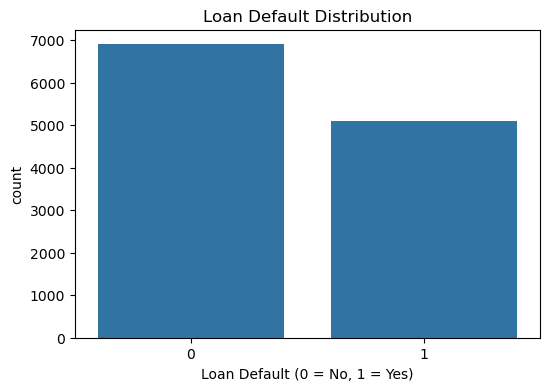

In [5]:
target_counts = df["loan_default"].value_counts()
print(target_counts)
print((target_counts / len(df) * 100).round(2))

plt.figure(figsize=(6,4))
sns.countplot(data=df, x="loan_default")
plt.title("Loan Default Distribution")
plt.xlabel("Loan Default (0 = No, 1 = Yes)")
plt.show()


## 4. Exploratory Data Analysis

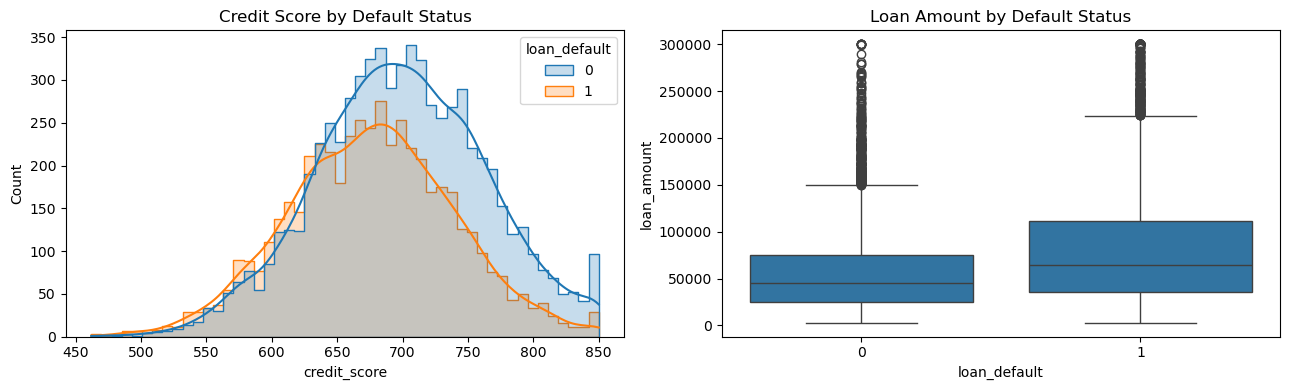

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13,4))

sns.histplot(data=df, x="credit_score", hue="loan_default", kde=True,
             element="step", ax=axes[0])
axes[0].set_title("Credit Score by Default Status")

sns.boxplot(data=df, x="loan_default", y="loan_amount", ax=axes[1])
axes[1].set_title("Loan Amount by Default Status")

plt.tight_layout()
plt.show()


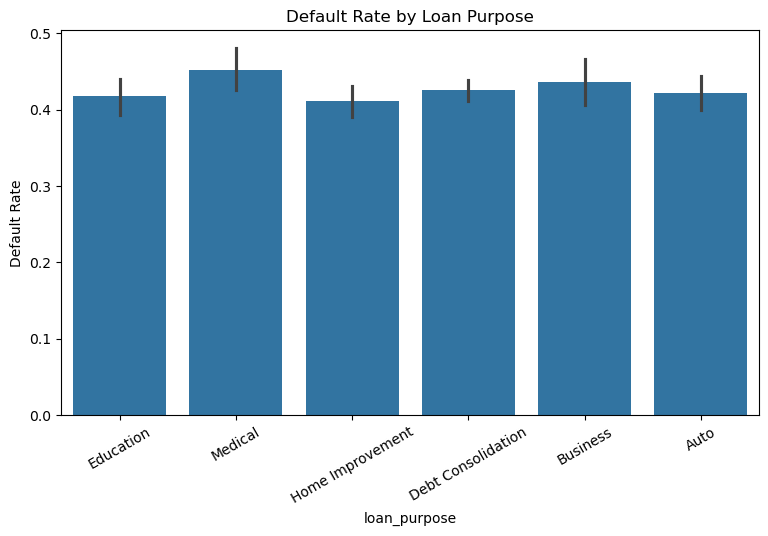

In [7]:
plt.figure(figsize=(9,5))
sns.barplot(data=df, x="loan_purpose", y="loan_default", estimator=np.mean)
plt.xticks(rotation=30)
plt.ylabel("Default Rate")
plt.title("Default Rate by Loan Purpose")
plt.show()


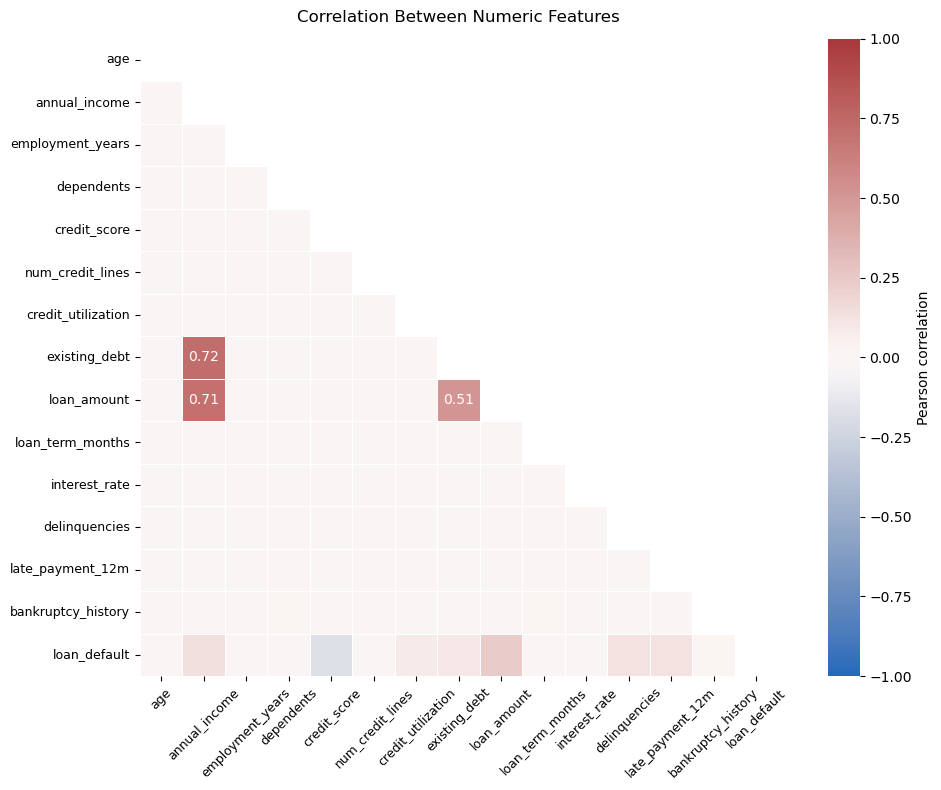

In [8]:
numeric_cols = df.select_dtypes(include=np.number).columns.drop("customer_id", errors="ignore")
corr = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
correlation_values = corr.to_numpy()
significant = np.abs(correlation_values) >= 0.25
annotations = np.full(correlation_values.shape, "", dtype=object)
annotations[significant] = np.char.mod("%.2f", correlation_values[significant])

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(
    corr,
    mask=mask,
    cmap="vlag",
    vmin=-1,
    vmax=1,
    center=0,
    annot=annotations,
    fmt="",
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Pearson correlation"},
    ax=ax
)
ax.set_title("Correlation Between Numeric Features", pad=12)
ax.tick_params(axis="x", labelrotation=45, labelsize=9)
ax.tick_params(axis="y", labelrotation=0, labelsize=9)
plt.tight_layout()
plt.show()

## 5. Feature Engineering

In [9]:
# Financial ratios often provide stronger signals than raw values.
df["debt_to_income"] = df["existing_debt"] / df["annual_income"]
df["loan_to_income"] = df["loan_amount"] / df["annual_income"]
df["payment_pressure"] = df["loan_amount"] / df["loan_term_months"]

# Prevent impossible/extreme ratio values from dominating the model.
df[["debt_to_income","loan_to_income","payment_pressure"]] = (
    df[["debt_to_income","loan_to_income","payment_pressure"]]
    .replace([np.inf, -np.inf], np.nan)
)

display(df[["annual_income","existing_debt","loan_amount",
            "debt_to_income","loan_to_income","payment_pressure"]].head())


,annual_income,existing_debt,loan_amount,debt_to_income,loan_to_income,payment_pressure
0,27713.0,16838,44558,0.607585,1.607837,1856.583333
1,63924.0,25372,62879,0.396909,0.983652,1047.983333
2,35097.0,9407,14206,0.268029,0.404764,295.958333
3,19792.0,11892,22423,0.600849,1.132932,934.291667
4,41852.0,9192,54351,0.219631,1.298648,1132.312500


## 6. Prepare Train/Test Data

In [10]:
X = df.drop(columns=["loan_default", "customer_id"])
y = df["loan_default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numeric_features = X.select_dtypes(exclude=["object"]).columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Default rate in train:", y_train.mean().round(4))
print("Default rate in test:", y_test.mean().round(4))


Train: (9600, 20) Test: (2400, 20)
Default rate in train: 0.4251
Default rate in test: 0.425


## 7. Baseline — Logistic Regression

In [11]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
])

logistic_model.fit(X_train, y_train)
lr_prob = logistic_model.predict_proba(X_test)[:, 1]
lr_pred = (lr_prob >= 0.50).astype(int)

print(classification_report(y_test, lr_pred))
print("ROC-AUC:", round(roc_auc_score(y_test, lr_prob), 4))


              precision    recall  f1-score   support

           0       0.72      0.69      0.71      1380
           1       0.61      0.64      0.63      1020

    accuracy                           0.67      2400
   macro avg       0.67      0.67      0.67      2400
weighted avg       0.68      0.67      0.67      2400

ROC-AUC: 0.7145


## 8. Random Forest

In [12]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=400,
        max_depth=12,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
rf_prob = rf_model.predict_proba(X_test)[:, 1]
rf_pred = (rf_prob >= 0.50).astype(int)

print(classification_report(y_test, rf_pred))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))


              precision    recall  f1-score   support

           0       0.70      0.76      0.72      1380
           1       0.63      0.55      0.59      1020

    accuracy                           0.67      2400
   macro avg       0.66      0.65      0.66      2400
weighted avg       0.67      0.67      0.67      2400

ROC-AUC: 0.6967


## 9. Gradient Boosting

In [13]:
gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))
])

gb_model.fit(X_train, y_train)
gb_prob = gb_model.predict_proba(X_test)[:, 1]
gb_pred = (gb_prob >= 0.50).astype(int)

print(classification_report(y_test, gb_pred))
print("ROC-AUC:", round(roc_auc_score(y_test, gb_prob), 4))


              precision    recall  f1-score   support

           0       0.68      0.81      0.74      1380
           1       0.65      0.47      0.55      1020

    accuracy                           0.67      2400
   macro avg       0.66      0.64      0.64      2400
weighted avg       0.66      0.67      0.66      2400

ROC-AUC: 0.7046


## 10. Model Comparison

In [14]:
def metric_row(name, y_true, pred, prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, prob)
    }

comparison = pd.DataFrame([
    metric_row("Logistic Regression", y_test, lr_pred, lr_prob),
    metric_row("Random Forest", y_test, rf_pred, rf_prob),
    metric_row("Gradient Boosting", y_test, gb_pred, gb_prob)
]).sort_values("ROC_AUC", ascending=False)

display(comparison.round(4))


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.6725,0.6085,0.6431,0.6254,0.7145
2,Gradient Boosting,0.6675,0.6488,0.4745,0.5481,0.7046
1,Random Forest,0.6696,0.6265,0.5510,0.5863,0.6967


## 11. Confusion Matrix and ROC Curve

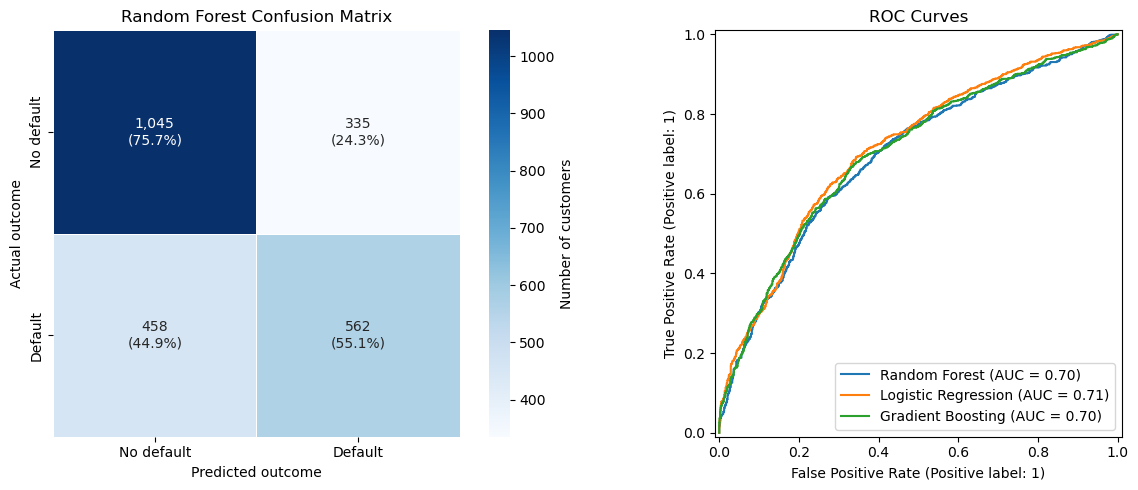

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, rf_pred, labels=[0, 1])
cm_percent = cm / cm.sum(axis=1, keepdims=True)
cm_annotations = np.array([
    [f"{count:,}\n({percent:.1%})" for count, percent in zip(row_counts, row_percentages)]
    for row_counts, row_percentages in zip(cm, cm_percent)
])
sns.heatmap(
    cm,
    annot=cm_annotations,
    fmt="",
    cmap="Blues",
    linewidths=0.5,
    linecolor="white",
    square=True,
    xticklabels=["No default", "Default"],
    yticklabels=["No default", "Default"],
    cbar_kws={"label": "Number of customers"},
    ax=axes[0]
)
axes[0].set_title("Random Forest Confusion Matrix")
axes[0].set_xlabel("Predicted outcome")
axes[0].set_ylabel("Actual outcome")

RocCurveDisplay.from_predictions(y_test, rf_prob, ax=axes[1], name="Random Forest")
RocCurveDisplay.from_predictions(y_test, lr_prob, ax=axes[1], name="Logistic Regression")
RocCurveDisplay.from_predictions(y_test, gb_prob, ax=axes[1], name="Gradient Boosting")
axes[1].set_title("ROC Curves")

plt.tight_layout()
plt.show()

## 12. Precision–Recall Curve

<Figure size 700x500 with 0 Axes>

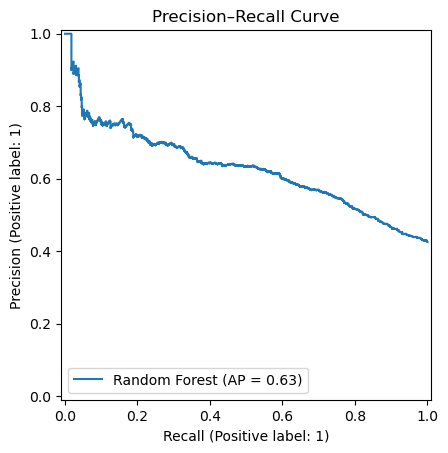

In [16]:
plt.figure(figsize=(7,5))
PrecisionRecallDisplay.from_predictions(y_test, rf_prob, name="Random Forest")
plt.title("Precision–Recall Curve")
plt.show()


## 13. Hyperparameter Tuning — Random Forest

In [ ]:
param_dist = {
    "model__n_estimators": [250, 400, 600],
    "model__max_depth": [8, 12, 16, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

tuning_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search = RandomizedSearchCV(
    tuning_pipe,
    param_distributions=param_dist,
    n_iter=15,
    scoring="roc_auc",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print("Best CV ROC-AUC:", round(search.best_score_, 4))
print("Best parameters:")
print(search.best_params_)


Fitting 5 folds for each of 15 candidates, totalling 75 fits


## 14. Evaluate Tuned Model

In [ ]:
best_model = search.best_estimator_
tuned_prob = best_model.predict_proba(X_test)[:, 1]
tuned_pred = (tuned_prob >= 0.50).astype(int)

print(classification_report(y_test, tuned_pred))
print("Test ROC-AUC:", round(roc_auc_score(y_test, tuned_prob), 4))


              precision    recall  f1-score   support

           0       0.68      0.77      0.72      1380
           1       0.62      0.51      0.56      1020

    accuracy                           0.66      2400
   macro avg       0.65      0.64      0.64      2400
weighted avg       0.66      0.66      0.65      2400

Test ROC-AUC: 0.6916


## 15. Threshold Analysis

,Threshold,Precision,Recall,F1
0,0.20,0.430,0.989,0.600
1,0.25,0.442,0.966,0.606
2,0.30,0.457,0.906,0.607
3,0.35,0.493,0.836,0.621
4,0.40,0.538,0.744,0.624
5,0.45,0.587,0.642,0.613
6,0.50,0.623,0.507,0.559
7,0.55,0.656,0.379,0.481
8,0.60,0.702,0.291,0.412
9,0.65,0.711,0.183,0.292


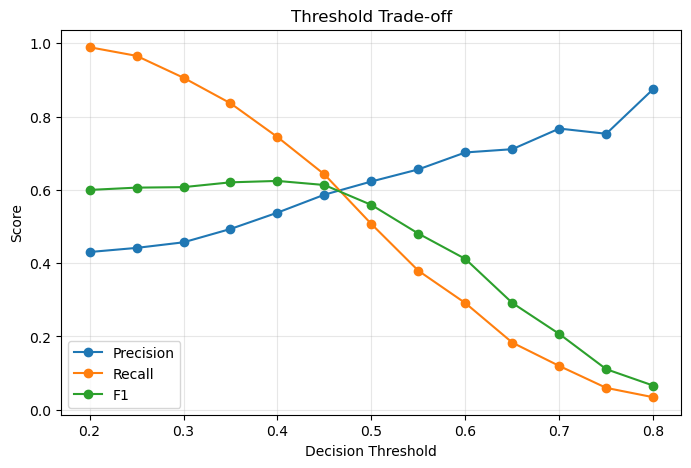

In [ ]:
thresholds = np.arange(0.20, 0.81, 0.05)
threshold_rows = []

for t in thresholds:
    pred = (tuned_prob >= t).astype(int)
    threshold_rows.append({
        "Threshold": t,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.round(3))

plt.figure(figsize=(8,5))
plt.plot(threshold_df["Threshold"], threshold_df["Precision"], marker="o", label="Precision")
plt.plot(threshold_df["Threshold"], threshold_df["Recall"], marker="o", label="Recall")
plt.plot(threshold_df["Threshold"], threshold_df["F1"], marker="o", label="F1")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Threshold Trade-off")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 16. Model Explainability — Permutation Importance

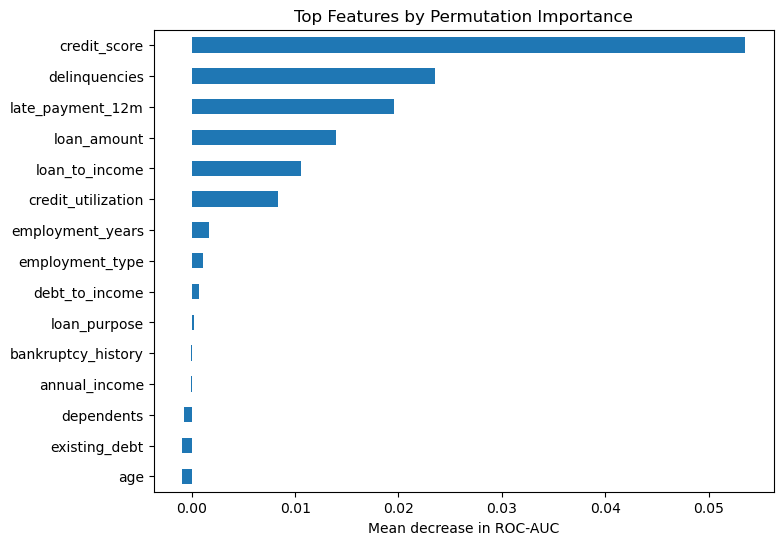

,importance
credit_score,0.053571
delinquencies,0.023569
late_payment_12m,0.019544
loan_amount,0.013931
loan_to_income,0.010524
credit_utilization,0.008359
employment_years,0.001679
employment_type,0.001082
debt_to_income,0.000684
loan_purpose,0.000214


In [ ]:
perm = permutation_importance(
    best_model, X_test, y_test,
    scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)

importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

plt.figure(figsize=(8,6))
importance.head(15).sort_values().plot(kind="barh")
plt.title("Top Features by Permutation Importance")
plt.xlabel("Mean decrease in ROC-AUC")
plt.show()

display(importance.head(15).to_frame("importance"))


## 17. Example: Score New Applicants

In [ ]:
sample_customers = X_test.head(5).copy()
sample_customers["predicted_default_probability"] = best_model.predict_proba(sample_customers)[:, 1]
sample_customers["risk_band"] = pd.cut(
    sample_customers["predicted_default_probability"],
    bins=[-np.inf, 0.30, 0.60, np.inf],
    labels=["Low", "Medium", "High"]
)

display(sample_customers[[
    "credit_score", "annual_income", "loan_amount",
    "credit_utilization", "predicted_default_probability", "risk_band"
]])


,credit_score,annual_income,loan_amount,credit_utilization,predicted_default_probability,risk_band
9335,706.0,61079.0,113701,0.598,0.479358,Medium
5342,705.0,50683.0,84425,0.337,0.455733,Medium
401,687.0,34316.0,67172,0.104,0.423548,Medium
9627,640.0,36333.0,28644,0.048,0.438479,Medium
4608,750.0,57632.0,72570,0.330,0.249882,Low


## 18. Save the Production-Style Pipeline

In [ ]:
joblib.dump(best_model, "credit_risk_model.joblib")
print("Saved: credit_risk_model.joblib")


Saved: credit_risk_model.joblib


## 19. Business Interpretation

- **Credit score, utilization, debt burden, delinquencies, and loan-to-income ratio** are expected to be important risk signals.
- A lender should not use accuracy alone; **ROC-AUC, precision, recall, F1, calibration, and threshold-specific business costs** should be considered.
- A lower threshold generally catches more potential defaults but can increase false positives.
- Model outputs should support human review and documented credit policies rather than automatically making high-impact decisions.
- Before production deployment, validate the model on out-of-time data, monitor drift, test subgroup performance, review fairness/legal requirements, and establish model governance.


## 20. Portfolio Deliverables

**Recommended GitHub files**
- `credit_risk_prediction.ipynb`
- `credit_risk_industry_dataset.csv`
- `credit_risk_model.joblib`
- `README.md`

**Resume project title:**  
**Credit Risk Prediction | Machine Learning & Financial Risk Analytics**

**Resume bullets:**
- Built an end-to-end credit risk classification pipeline using Python, Scikit-learn, preprocessing pipelines, and ensemble ML models.
- Performed data quality checks, EDA, missing-value treatment, ratio-based feature engineering, model comparison, and hyperparameter tuning.
- Evaluated models using ROC-AUC, precision, recall, F1-score, confusion matrix, ROC/PR curves, and decision-threshold analysis.
